## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

#### 1 часть
1) определение импульсной характеристики, передаточной функции, линейное разностное уравнение

**Определение** Линейное разностное уравнение - уравнение вида:
$$
y(n) = \sum_{i = 0}^{N - 1} b_i x(n - i) - \sum_{k = 1}^{M - 1} a_k y(n - k)
$$, где порядок разностного уравнения = $max(N-1, M-1)$

**Определение** Импульсная характеристика - реакция системы на единичный цифровой импульс при нулевых начальных условиях, для линейных систем:
$$
h(n) = \sum_{i = 0}^{N - 1} b_i u_{0}(n - i) - \sum_{k = 1}^{M - 1} a_k h(n - k)
$$

**Определение** Передаточная функция - импульсная характеристика в Z области
$$
\mathcal{Z}\{h(n)\} = H(z) = \sum_{n = 0}^{+\infty} h(n) z^{-n}
$$


2) формула свертка, реакция через свертку, БИХ

**Определение** Сверткой двух сигналов называется следующая операция:
$$
y(n) = x(n) * h(n) = \sum_{m = 0}^{+\infty} h(m)x(n - m)
$$
***NB*** Свертка входного сигнала с импульсной характеристики системы равна реакции системы 

**Определение** Импульсная характеристика системы называется бесконечной, если выход системы зависит не только от текущих и прошлых входных данных, но и от предыдущих значений самого выхода.

3) Нули, полюса ПФ, алгебраическая форма записи, показательная форма записи

**Определение**
Нуль передаточной функции - значение $z = z_0$, при котором передаточная функция принимает нулевое значение.

**Определение**
Полюс передаточной функции - значение $z = z^*$ такое, что $\lim_{z \rightarrow z^*} H(z) = \infty$

***NB*** Связь форм записи комплексного числа.

Алгебраическая форма записи: $z = x + jy$ в декартовой системе координат.

Тригонометрическая форма записи: $z = |z|(cos(\phi) + jsin(\phi))$ в полярных координатах.

Показательная форма записи: $z = |z|e^{j\phi}$

4) Критерий устойчивости по значениям полюсов

**Критерий** ЛДС устойчива $\Leftrightarrow$ $\sum_{n = 0}^{\infty} |h(n)| < \infty$

**Критерий** ЛДС устойчива $\Leftrightarrow$ все полюса ПФ находятся внутри круга единичного радиуса: $\forall i |z^{*}_{i}| < 1$


5) АЧХ, ФЧХ

**Определение** Амплитудно-частотной характеристикой системы называется $A(\hat{\omega}) = |\sum_{n = 0}^{\infty} h(n)e^{-j \hat{\omega} n}|$

**Определение** Фазо-частотной характеристикой системы называется $\Phi(\hat{\omega}) = arg\{\sum_{n = 0}^{\infty} h(n)e^{-j \hat{\omega} n}\}$

#### 2 часть
1) ДПФ, ОДПФ

**Определение** Дискретным преобразованием Фурье периодической последовательности длины N называется:
$$
\mathcal{F}\{x(n)\} = X(k) = \sum_{n = 0}^{N - 1} x(n) e^{-j \dfrac{2 \pi k}{N} n}
$$

**Определение** Обратным дискретным преобразованием Фурье периодической последовательности длины N называется:
$$
\mathcal{F}^{-1}\{X(k)\} = x(n) = \dfrac{1}{N} \sum_{k = 0}^{N - 1} X(k) e^{j \dfrac{2 \pi k}{N} n}
$$

2) Амплитудный, фазовый спектры

**Определение** Амплитудный спектр периодического сигнала длины N равен $A(k) = \dfrac{1}{N}|X(K)|$

**Определение** Фазовый спектр периодического сигнала длины N равен $\Phi(k) = arg\{X(K)\}$ для тех гармоник, у которых $|X(k)| \ne 0$

3) Формула для восстановления сигнала из последовательности

**NB** Аналоговый сигнал
$$
x(t) = \dfrac{1}{N} \sum_{k = -\frac{N}{2}}^{\dfrac{N}{2} - 1} X_a(k) e^{j  \dfrac{2 \pi k}{NT} t}
$$ 
4) Равенство Парсеваля

**NB** Равенство Парсеваля
$$
\sum_{n = 0}^{N - 1} |x(n)|^{2} = \dfrac{1}{N}\sum_{k = 0}^{N-1} |X(k)|^{2}
$$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Часть 1

#### 1) Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i$, $a_k$ и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

Где вариант $N_{var} = 2$

In [3]:
import numpy as np
n_var = 2

impulse_response_len = (n_var % 10) + 20

b_0 = 0.5 + 0.02 * n_var
b = np.array([
    b_0,
    b_0 * np.pow(-1, n_var + 1) * (0.9822 + 0.0178 * n_var),
    b_0 * (0.8 + 0.2 * (n_var % 5))
], dtype=np.float32)

a = np.array([
    1.0,
    np.pow(-1, n_var) * (0.7778 + 0.025 * n_var),
    0.64 + 0.006 * n_var
], dtype=np.float32)

In [4]:
def system_response(b: np.ndarray, a: np.ndarray, input_signal: np.ndarray, n: int): # задали разностное уравнение
    out_signal = []
    
    for i in range(n):
        x = [input_signal[i - j] if i >= j else 0.0 for j in range(len(b))]
        y = [out_signal[i - j] if i >= j else 0.0 for j in range(1, len(a))]

        res = np.sum(b * x) - np.sum(a[1:] * y)
        out_signal.append(res)

    return out_signal

impulse_signal = np.array([1.0] + [0.0] * (impulse_response_len-1)) # единичный импульс в момент t=0
impulse_response = system_response(b, a, impulse_signal, impulse_response_len) # реакция системы

Начальные условия: $h[-1] = h[-2] = 0$.
На графике показаны первые 22 отсчёта.

Text(0, 0.5, 'h(n), impulse response function')

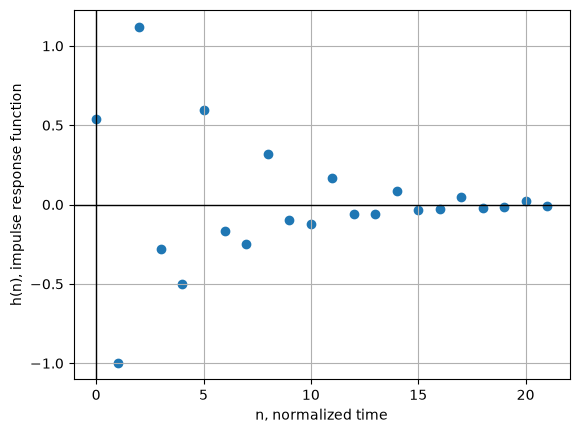

In [5]:
import matplotlib.pyplot as plt

plt.scatter(range(len(impulse_response)), impulse_response)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.grid(True)
plt.xlabel("n, normalized time")
plt.ylabel("h(n), impulse response function")

По передаточной функции можно точно восстановить разностное уравнение, а по разностному уравнению можно записать импульсную характеристику системы.

$H(z) = \dfrac{b_0 + b_1z^{-1} + b_2z^{-2}}{1 + a_1z^{-1} + a_2z^{-2}}$ $\Rightarrow$ $y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n - 1) - a_2 y(n-2)$, а импульсная характеристика по определению реакция системы на цифровой единичный импульс, т.е. $x(n) = u_0(n)$

$$h(n) = b_0 u_0(n) + b_1 u_0(n-1) + b_2 u_0(n-2) - a_1 h(n - 1) - a_2 h(n-2) $$

Так как разностное уравнение задает рекурсивную ЛС, то её импульсная характеристика имеет бесконечную длину (причем из графика видно, что система сходится к нулю со временем и стабилизируется при подаче единичного импульса на вход)

#### 2) Вычислить реакцию $y_1(n)$ по формуле свёртки. В качестве воздействия $x(n)$ длины $N_2$ выбрать дискретный прямоугольный импульс:
   $$
   x(n) =
   \begin{cases}
   1, & 0 \le n < \operatorname{int}(N_2/2),\\
   0, & \operatorname{int}(N_2/2) \le n \le N_2-1.
   \end{cases}
   $$

   где функция $\operatorname{int}(t)$ — округление до ближайшего целого.

   Вывести графики воздействия и реакции.

   Пояснить:
   1. Чему равна длина импульса $x$.
   2. Чему равна длина свёртки аналитически и по графику.
   3. Почему её ограничивают до длины воздействия.


Ненулевая часть входного импульса длится 16 отсчётов.

Text(0, 0.5, 'x(n)')

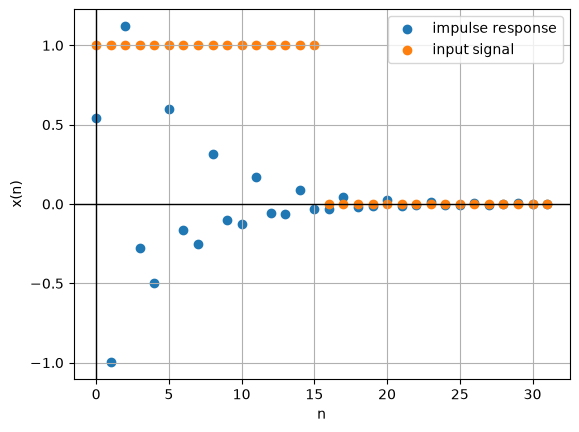

In [6]:
input_length = (n_var % 10) + 30
step_signal = [1 if i < input_length // 2 else 0 for i in range(0, input_length)]

impulse_signal = np.array([1.0] + [0.0] * (input_length-1))
impulse_response = system_response(b, a, impulse_signal, input_length)

plt.scatter(range(input_length), impulse_response, label="impulse response")
plt.scatter(range(input_length), step_signal, label="input signal")
plt.legend()
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.grid(True)
plt.xlabel("n")
plt.ylabel("x(n)")

Свертка сигналов вычисляется по следующей формуле $$y(n) = x(n) * h(n) = \sum_{m=-\infty}^{+\infty} h(n - m) x(m)$$

и в общем случае входное воздействие x может быть любой длины, в том числе и бесконечной, как и реакция системы y. В нашем случае система задана с нулевыми начальными условиями + длина входного воздействия ограничена $N_2$ = 32. Полная свёртка двух массивов длиной 32 имеет длину $32 + 32 - 1 = 63$ отсчёта. Однако истинная импульсная характеристика данной системы бесконечна, поэтому её реакция на заданный импульс также имеет бесконечную длину. В коде вычисляются и отображаются только первые $N_2 = 32$ отсчёта реакции. Это позволяет сравнить результаты свёртки и разностного уравнения на одном периоде. Ограничение графика не означает, что последующие отсчёты реакции равны нулю.

Проверка на корректность вычислений:  True


Text(0, 0.5, 'y_1(n)')

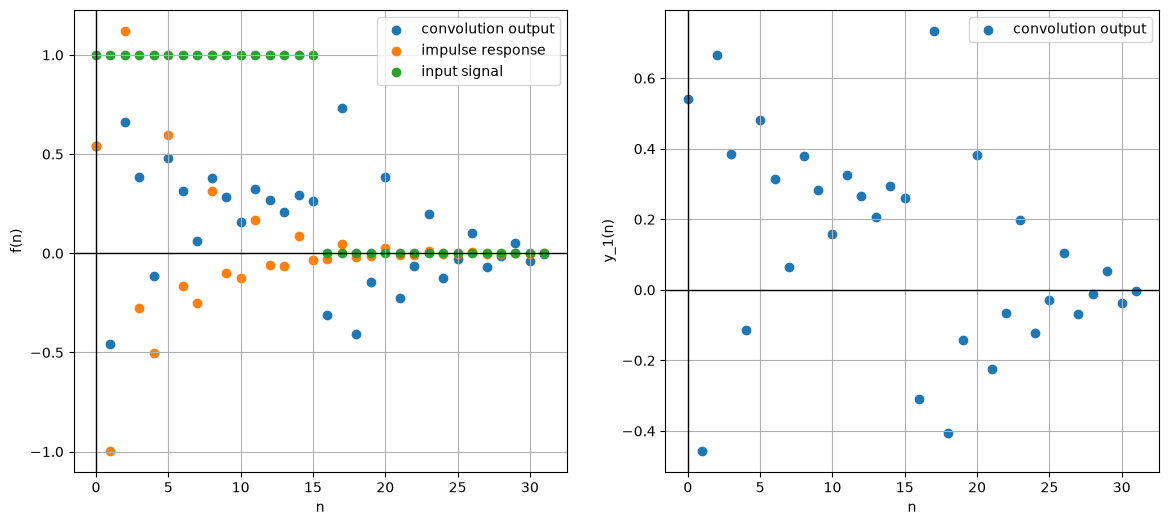

In [7]:
from scipy.signal import lfilter
output_scipy = lfilter(b, a, step_signal)

output_my = []

for i in range(input_length):
    s = 0.0
    for j in range(0, i + 1):
        s += step_signal[j] * impulse_response[i - j]
    output_my.append(s)

print("Проверка на корректность вычислений: ", all(np.isclose(output_scipy, output_my)))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].scatter(range(len(output_my)), output_my, label="convolution output")
ax[0].scatter(range(len(impulse_response)), impulse_response, label="impulse response")
ax[0].scatter(range(len(step_signal)), step_signal, label="input signal")
ax[0].legend()
ax[0].grid(True)
ax[0].axhline(0, color='black', linewidth=1)
ax[0].axvline(0, color='black', linewidth=1)
ax[0].set_xlabel("n")
ax[0].set_ylabel("f(n)")

ax[1].scatter(range(len(output_my)), output_my, label="convolution output")
ax[1].legend()
ax[1].grid(True)
ax[1].axhline(0, color='black', linewidth=1)
ax[1].axvline(0, color='black', linewidth=1)
ax[1].set_xlabel("n")
ax[1].set_ylabel("y_1(n)")

#### 3) Вычислить реакцию $y_2(n)$ по разностному уравнению. Задать воздействие $x(n)$ из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1(n)$ и $y_2(n)$. 
Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

In [8]:
print("Коэффициенты разностного уравнения:", b, a)

Коэффициенты разностного уравнения: [ 0.54     -0.549612  0.648   ] [1.     0.8278 0.652 ]


Разностное уравнение с заданными коэффициентами выглядит следующим образом (коэффициенты округлены до 2 знака после запятой):
$$y(n) = 0.54x(n) - 0.55x(n-1) + 0.65x(n-2) - 0.83y(n - 1) - 0.65y(n-2)$$

Так как заданное разностное уравнение имеет БИХ, то длину реакции ограничиваем длиной воздействия $N_2$. Длина массива воздействия равна 32 отсчётам. Для сравнения двух способов расчёта вычислены первые 32 отсчёта. Реакции, полученные свёрткой и по разностному уравнению, на этом интервале совпадают с точностью вычислений.

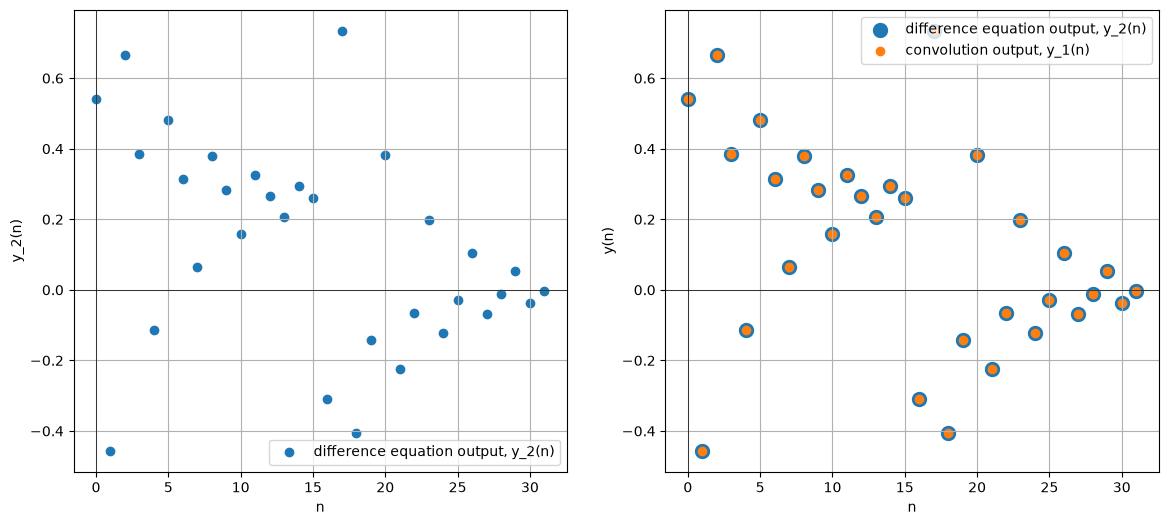

In [9]:
output_signal = system_response(b, a, step_signal, len(step_signal))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].scatter(range(len(output_signal)), output_signal, label="difference equation output, y_2(n)")
ax[0].grid(True)
ax[0].axhline(0, color='black', linewidth=0.5)
ax[0].axvline(0, color='black', linewidth=0.5)
ax[0].set_xlabel("n")
ax[0].set_ylabel("y_2(n)")
ax[0].legend()

ax[1].scatter(range(len(output_signal)), output_signal, label="difference equation output, y_2(n)", linewidths=5)
ax[1].scatter(range(len(output_my)), output_my, label="convolution output, y_1(n)")
ax[1].grid(True)
ax[1].axhline(0, color='black', linewidth=0.5)
ax[1].axvline(0, color='black', linewidth=0.5)
ax[1].set_xlabel("n")
ax[1].set_ylabel("y(n)")
ax[1].legend()

#### 4) Вычислить нули и полюсы передаточной функции. Нули и полюсы представить в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно $\pi$. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.


In [10]:
from scipy.signal import tf2zpk

zeros, poles, gain = tf2zpk(b, a) # функция вычисляет разложение на простые множители числителя и знаменателя

print(f"Нули ПФ: {zeros}, \nПолюса ПФ: {poles}, \nКоэффициент усиления ПФ: {gain}")

Нули ПФ: [0.5089+0.97006226j 0.5089-0.97006226j], 
Полюса ПФ: [-0.4139+0.6933158j -0.4139-0.6933158j], 
Коэффициент усиления ПФ: 0.5400000214576721


Пакет scipy.signal возвращает значения в алгебраической форме:
$$z_{0_1} = 0.51 + 0.97j; \quad z_{0_2} = 0.51 - 0.97j$$
$$z^{*}_{0} = -0.41 + 0.69j; \quad z^{*}_{1} = -0.41 - 0.69j$$

Показательная форма комплексного числа: $|z|e^{i\phi}=|z|(cos(\phi) + jsin(\phi))$, где $|z| = \sqrt{x^2 + y^2}$ и $\phi = arg{z} = atan2(y, x)$

In [11]:
z0 = zeros[0]
z0_len = np.sqrt(np.real(z0) ** 2 + np.imag(z0) ** 2)
z0_phi = np.rad2deg(np.atan2(np.imag(z0), np.real(z0)))

zstar = poles[0]
zstar_len = np.sqrt(np.real(zstar) ** 2 + np.imag(zstar) ** 2)
zstar_phi = np.rad2deg(np.atan2(np.imag(zstar), np.real(zstar)))

print(f"|z0| = {z0_len}; arg(z0) = {z0_phi}")
print(f"|z*| = {zstar_len}; arg(z*) = {zstar_phi}")

|z0| = 1.095445156097412; arg(z0) = 62.31824493408203
|z*| = 0.8074651956558228; arg(z*) = 120.83661651611328


In [12]:
print(z0_phi / 180.0)
print(zstar_phi / 180.0)

0.34621248
0.67131454


Показательная форма нулей и полюсов:
$$z_{0}^{0} = 1.1e^{62.3^{\circ}j} = 1.1e^{0.35 \pi j}; \quad z_{1}^{0} = 1.1e^{-62.3^{\circ}j} = 1.1e^{-0.35 \pi j}$$
$$z^{*}_{0} = 0.8e^{120.8^{\circ}j} = 0.8e^{0.67 \pi j}; \quad z^{*}_{1} = 0.8e^{-0.67 \pi j}$$

Передаточная функция выраженная через простые множители в показательной форме:

$$H(z) = \dfrac{0.54 - 0.55z^{-1} + 0.65z^{-2}}{1 + 0.83z^{-1} + 0.65z^{-2}} = \dfrac{0.54z^2 - 0.55z + 0.65}{z^2 + 0.83z + 0.65} = K\dfrac{(z - z_{0}^{0})(z - z_{1}^{0})}{(z - z_{0}^{*})(z - z_{1}^{*})} = 0.54\dfrac{(z - 1.1e^{0.35 \pi j})(z - 1.1e^{-0.35 \pi j})}{(z - 0.8e^{0.67 \pi j})(z - 0.8e^{-0.67 \pi j})}$$

#### 5) Изобразить карту нулей и полюсов. Пояснить:
- Является ли рекурсивное звено устойчивым.
- Совпадают ли значения нулей и полюсов с вычисленными в п. 4.

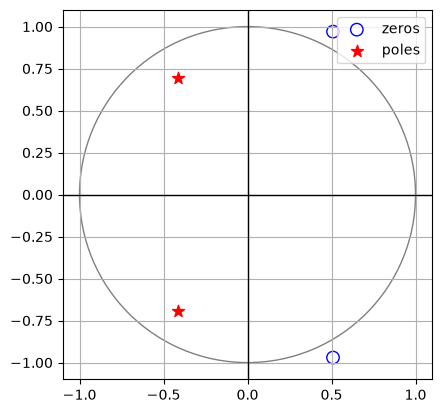

In [13]:
fig, ax = plt.subplots()

ax.scatter(zeros.real, zeros.imag, marker='o', facecolors='none', edgecolors='blue', s=80, label='zeros')

ax.scatter(poles.real, poles.imag, marker='*', color='red', s=80, label='poles')

circle = plt.Circle((0, 0), 1, fill=False, color='gray')
ax.add_patch(circle)
ax.axhline(0, color='black', linewidth=1)
ax.axvline(0, color='black', linewidth=1)

ax.set_aspect('equal')
ax.grid()
ax.legend()
plt.show()

Так как все полюса ПФ простые и находятся внутри единичной окружности, по Теореме об устойчивости, ЛДС - является устойчивой.
Координаты на карте нулей и полюсов совпадают с пунктом 4

### 6) Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $\hat{\omega}$ и вывести их графики.

Пояснить:
1. Чему равны границы основной полосы частот.
2. Соответствие между картой нулей и полюсов и видом АЧХ.
3. Какому значению АЧХ соответствует скачок на $\pi$, если он имеется.
4. Какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.


В прошлом задании было вычислено разложение ПФ на простые множители: $$H(z) = K \dfrac{\prod_{i} (z - z_{0}^{(i)})}{\prod_{j} (z - z_{p}^{(j)})}$$

для анализа АЧХ и ФЧХ на вход ПФ подают гармоническое колебание: $H(e^{\hat{\omega}j})$ и изучают модуль и аргумент ПФ.

$$H(e^{\hat{\omega}j}) = K \dfrac{\prod_{i} (e^{\hat{\omega}j} - z_{0}^{(i)})}{\prod_{k} (e^{\hat{\omega}j} - z_{p}^{(k)})}$$

АЧХ: $A(\hat{\omega}) = |H(e^{\hat{\omega}j})| = |K| \dfrac{\prod_{i} |e^{\hat{\omega}j} - z_{0}^{(i)}|}{\prod_{k} |e^{\hat{\omega}j} - z_{p}^{(k)}|}$

ФЧХ: $\phi(\hat{\omega}) = argH(e^{\hat{\omega}j})$

Так как все коэффициент ПФ вещественные числа, а $e^{\hat{\omega}j} = e^{(\hat{\omega} + 2\pi)j} $ - периодическая функция, то для её исследования достаточно рассмотреть $\hat{\omega} \in [0, \pi)$, так как коэффициенты системы вещественные, $H(e^{-j\hat{\omega}}) = \overline{H(e^{j\hat{\omega}})}$. Поэтому АЧХ является чётной, а фазы при противоположных частотах имеют противоположные знаки с точностью до $2\pi$. Для исследования достаточно односторонней полосы $0 \le \hat{\omega} \le \pi$.

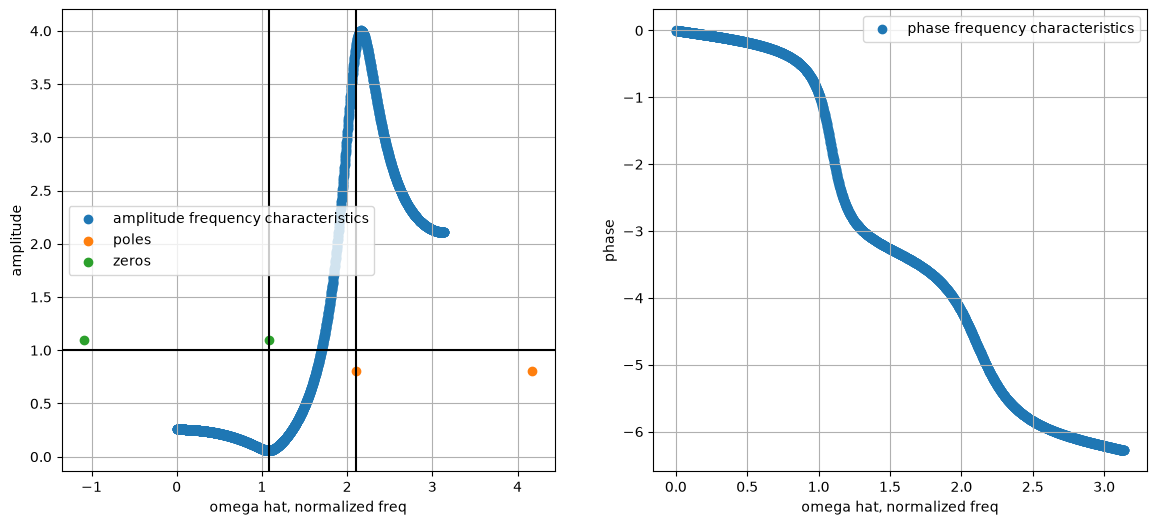

In [14]:
from scipy.signal import freqz

w, h = freqz(b, a, 2048) # подставляет гармонику и вычисляет значения ПФ для w = linspace(0, pi, N) 

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
amp = [np.linalg.norm(h[i]) for i in range(len(h))]
phi = np.unwrap([np.atan2(h[i].imag, h[i].real) for i in range(len(h))])
ax[0].scatter(w, amp, label="amplitude frequency characteristics")
ax[0].axhline(1, c="black")
ax[0].axvline(np.angle(poles[0]), c="black")
ax[0].scatter(np.unwrap(np.angle(poles)), np.abs(poles), label="poles")
ax[0].axvline(np.angle(zeros[0]), c="black")
ax[0].scatter(np.unwrap(np.angle(zeros)), np.abs(zeros), label="zeros")
ax[0].grid(True)
ax[0].set_xlabel("omega hat, normalized freq")
ax[0].set_ylabel("amplitude")
ax[0].legend()

ax[1].scatter(w, phi, label="phase frequency characteristics")
ax[1].grid(True)
ax[1].set_xlabel("omega hat, normalized freq")
ax[1].set_ylabel("phase")
ax[1].legend()

Из левого графика видно, что близи полюсов ПФ наблюдаются локальные максимумы АЧХ, а вблизи нулей наоборот локальные минимумы.
Это объясняется тем, что $|e^{j\hat{\omega}} - z_i|$ - расстояние от точки $e^{j\hat{\omega}}$ на единичной окружности до нуля или полюса
передаточной функции.
Поэтому чем ближе гармоника к нулю ПФ, тем меньше становится амплитуда (потому что эта скобка в числителе).
В случае когда гармоника близка к полюсу ПФ, тем больше становится амплитуда.

Но из графиков видно, что минимумы и максимумы достигаются не идеально в точках с нулями/полюсами, это потому что вклад вносят сразу два полюса/нуля.

Скачков на pi на графиках нет, оба графика непрерывны на отрезке $[0, \pi)$.

Из графика АЧХ видно, что низкие частоты из интервала $(0, 1.1)$ сильно подавляются системой, а частоты из интервала $(1.8, 2.2)$ наоборот сильно усиливаются. 

#### 7) Вычислить АЧХ и ФЧХ в шкале частот $f$ (Гц) при заданной частоте дискретизации $f_{\text{д}}$ и вывести их графики.

Пояснить:
1. Чему равны границы основной полосы частот.
2. Соответствие частотами $\hat{\omega}$ и $f$.

Перевод из нормализованный шкалы и обратно устроен следующим образом:
$\omega = 2\pi f = \dfrac{2\pi}{T}$

$\hat{\omega} = \dfrac{\omega}{f_{discrete}} = \dfrac{2 \pi f}{f_{discrete}}$

Так как раньше $\hat{\omega} \in [0, \pi)$ было, то теперь $f = \dfrac{\hat{\omega}f_{discrete}}{2\pi} \in [0, \dfrac{f_{discrete}}{2}]$

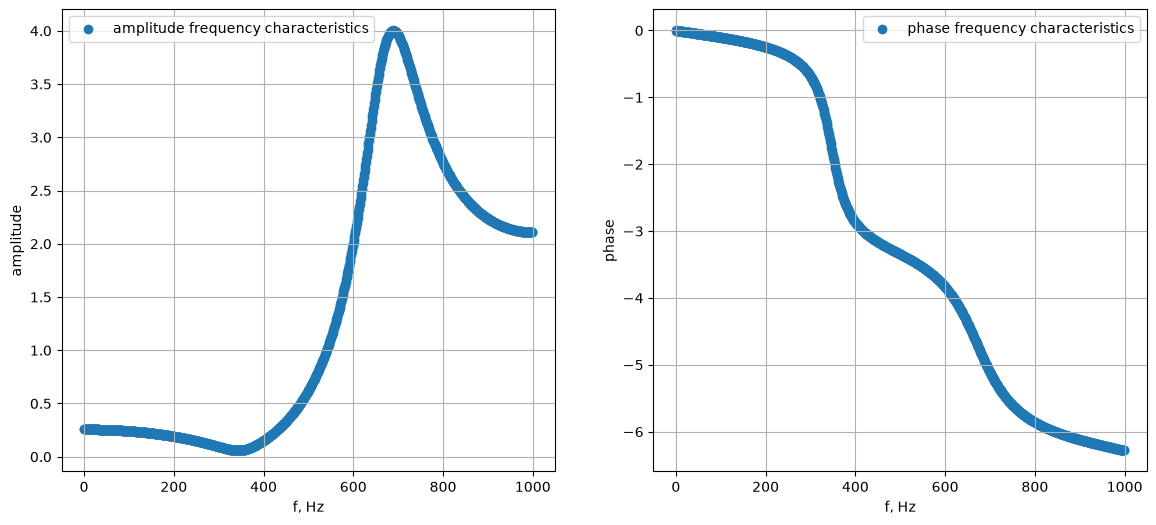

In [15]:
f_discrete = 1_000 * n_var

w, h = freqz(b, a, 1024, fs=f_discrete)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
amp = [np.linalg.norm(h[i]) for i in range(len(h))]
phi = np.unwrap([np.atan2(h[i].imag, h[i].real) for i in range(len(h))])
ax[0].scatter(w, amp, label="amplitude frequency characteristics")
ax[0].grid(True)
ax[0].set_xlabel("f, Hz")
ax[0].set_ylabel("amplitude")
ax[0].legend()

ax[1].scatter(w, phi, label="phase frequency characteristics")
ax[1].grid(True)
ax[1].set_xlabel("f, Hz")
ax[1].set_ylabel("phase")
ax[1].legend()

### Часть 2

#### 1) Вычислить амплитудный и фазовый спектры периодической последовательности $x(n)$ с периодом $N$:

   $$
   x(nT) = A_1 \cos(2\pi f_1 nT + \pi/4) + A_2 \cos(2\pi f_2 nT + \pi/8)
   $$

   Вывести графики последовательности $x(n)$ на периоде $N$ в шкале дискретного и дискретного нормированного времени.


In [16]:
seq_len = 64 # длина/период последовательности
f_discrete = 2000 * (n_var % 5 + 1) # частота дискретизации
T = 1 / f_discrete # период дискретизации
A = np.array([1 + 0.01 * n_var, 2 * (1 + 0.01 * n_var)]) # амплитуды A1 A2
F = np.array([f_discrete / 8, 1.5 * f_discrete / 8]) # частоты f1 f2

Вычислим амплитудный и фазовый спектры в лоб: $cos(\omega n + \phi) = \dfrac{e^{j (\omega n + \phi)} + e^{-j (\omega n + \phi)}}{2}$, тогда 

$$x(nT) = \dfrac{A_1}{2}(e^{j (2\pi f_1 nT + \pi / 4)} + e^{-j (2\pi f_1 nT + \pi / 4)}) + \dfrac{A_2}{2}(e^{j (2\pi f_2 nT + \pi / 8)} + e^{-j (2\pi f_2 nT + \pi / 8)})$$

из выражения видно, что в $f = \pm f_1$ фаза равна $\phi = \pm \pi / 4$, а амплитуда $A = \dfrac{A_1}{2}$, а соответственно в $f = \pm f_2$ фаза равна $\phi = \pm \pi / 8$, а амплитуда $A = \dfrac{A_2}{2}$

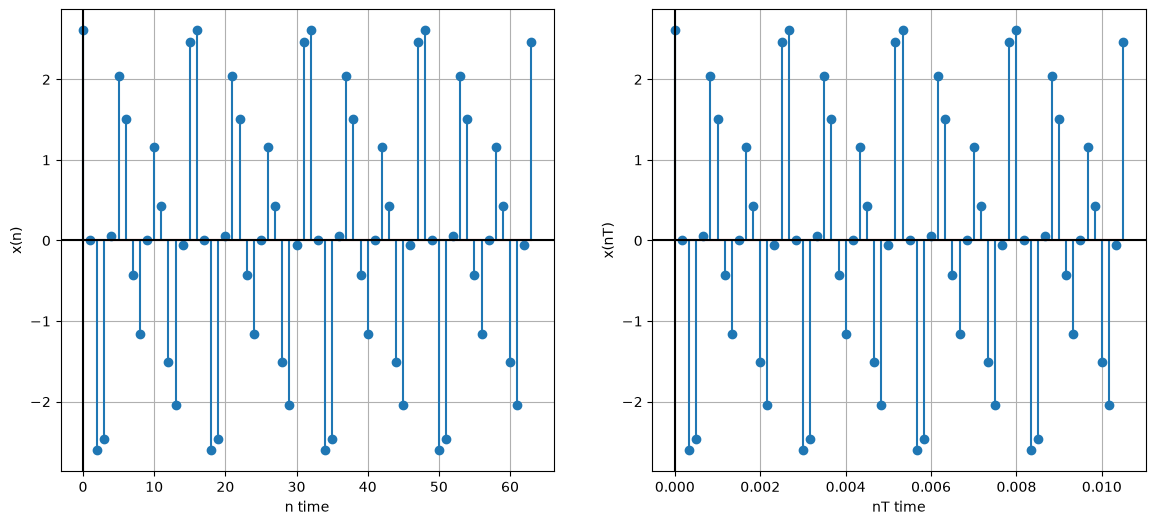

In [17]:
x = lambda n: np.sum(A*np.array([np.cos(2*np.pi*F[0]*n*T + np.pi/4), np.cos(2*np.pi*F[1]*n*T + np.pi/8)])) # x(nT)

seq = np.array(list(map(x, range(seq_len)))) # значения x(nT) на периоде в дискретном времени

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
time_n = range(seq_len)
ax[0].stem(time_n, seq, label="x(n) seq")
ax[0].grid(True)
ax[0].set_xlabel("n time")
ax[0].set_ylabel("x(n)")
ax[0].axhline(0, c="black")
ax[0].axvline(0, c="black")

time_nt = list(map(lambda x: x*T, range(0, seq_len)))
ax[1].stem(time_nt, seq, label="x(n) seq")
ax[1].set_xlabel("nT time")
ax[1].set_ylabel("x(nT)")
ax[1].axhline(0, c="black")
ax[1].axvline(0, c="black")
ax[1].grid(True)

In [18]:
from typing import Tuple

def dft(input_seq: np.ndarray, inv: bool=False) -> Tuple[np.ndarray, np.ndarray]:
    n = len(input_seq)

    output_seq = []
    w = []

    multiplier = (1.0 if not inv else 1.0/n)
    sign = (+1 if inv else -1)

    for k in range(n):
        s = 0.0 + 0.0j
        wk = 2 * np.pi * k / n
        for i in range(n):
            s += input_seq[i] * np.exp(wk * i * 1j * sign)
        w.append(wk)
        output_seq.append(s * multiplier)
    
    return np.array(w), np.array(np.real_if_close(output_seq, tol=1e-6))

#### 2) Вычислить ОДПФ от ДПФ последовательности $x(n)$ и вывести график полученной последовательности в шкале дискретного нормированного времени.


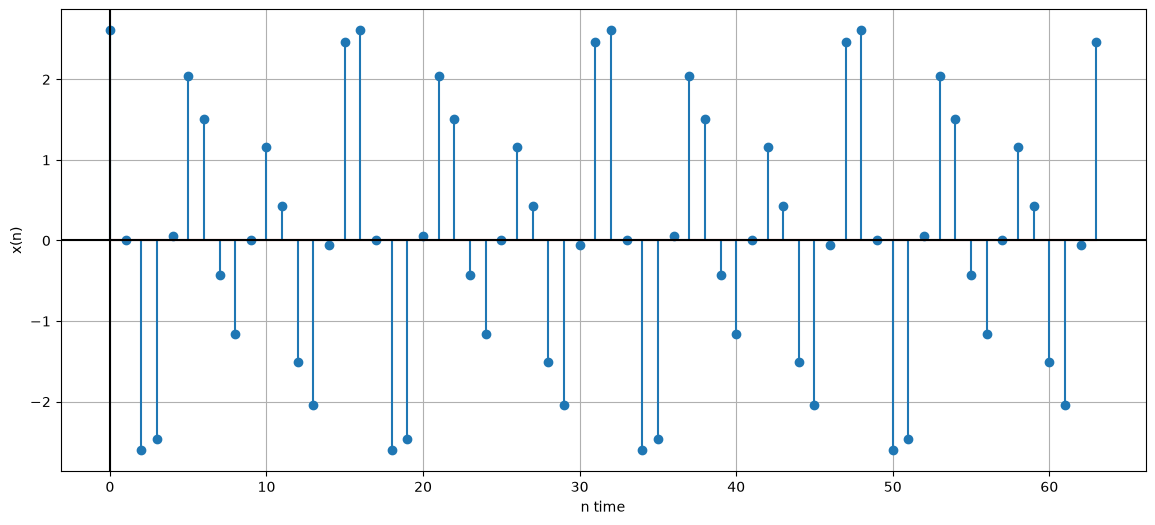

In [19]:
w, h = dft(seq)
_, orig_seq = dft(h, True)

fig, ax = plt.subplots(figsize=(14, 6))
time_n = range(seq_len)
ax.stem(time_n, orig_seq, label="x(n) seq")
ax.grid(True)
ax.set_xlabel("n time")
ax.set_ylabel("x(n)")
ax.axhline(0, c="black")
ax.axvline(0, c="black")

#### 3) Вычислить амплитудный и фазовый спектры последовательности $x(n)$ и вывести их графики в шкалах дискретных нормированных и абсолютных частот.

   Пояснить:
   1. Связь дискретного нормированного времени с дискретным временем.
   2. Связь частоты $f$ (Гц) с дискретной нормированной частотой.
   3. Вид амплитудного и фазового спектров.


Дискретное время выражается как $t = nT_{discrete}$, где n - целое, а T - период дискретизации, а нормированное дискретное время выражается как $\hat{t} = \dfrac{t}{T_{discrete}} = n$

Дискретная нормированная частота: $\hat{f} = fT_{discrete} = \dfrac{f}{f_{discrete}}$

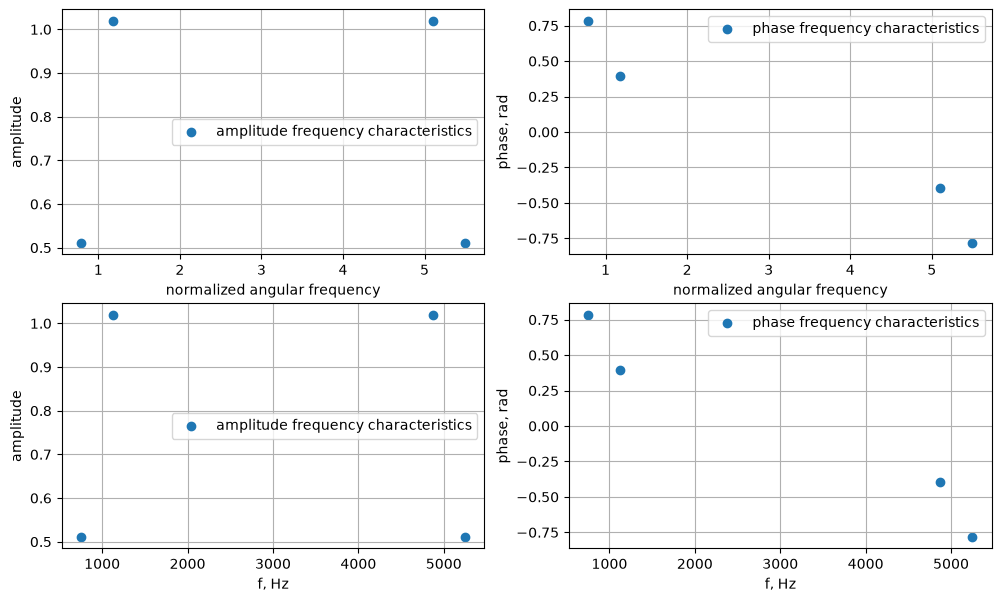

In [20]:
amp = np.abs(h) / seq_len
phi = np.angle(h)

mask = amp > 1e-8 * np.max(amp) # убираем маленькие числа, которые возникли из-за численных ошибок

fig, ax = plt.subplots(2, 2, figsize=(12, 7))

ax[0, 0].scatter(w[mask], amp[mask], label="amplitude frequency characteristics")
ax[0, 0].grid(True)
ax[0, 0].set_xlabel("normalized angular frequency")
ax[0, 0].set_ylabel("amplitude")
ax[0, 0].legend()

ax[0, 1].scatter(w[mask], phi[mask], label="phase frequency characteristics")
ax[0, 1].grid(True)
ax[0, 1].set_xlabel("normalized angular frequency")
ax[0, 1].set_ylabel("phase, rad")
ax[0, 1].legend()

freq_hz = w * f_discrete / (2 * np.pi)
ax[1, 0].scatter(freq_hz[mask], amp[mask], label="amplitude frequency characteristics")
ax[1, 0].grid(True)
ax[1, 0].set_xlabel("f, Hz")
ax[1, 0].set_ylabel("amplitude")
ax[1, 0].legend()

ax[1, 1].scatter(freq_hz[mask], phi[mask], label="phase frequency characteristics")
ax[1, 1].set_xlabel("f, Hz")
ax[1, 1].set_ylabel("phase, rad")
ax[1, 1].grid(True)
ax[1, 1].legend()

Амплитудный спектр является линейчатым

$|X(f_1)| = |X(-f_1)| = \dfrac{A_1}{2}$

$|X(f_2)| = |X(-f_2)| = \dfrac{A_2}{2}$

Фазовый спектр тоже является линейчатым

$\phi(\pm f_1) = \pm \pi/4$

$\phi(\pm f_2) = \pm \pi/8$ 

#### 4) Вычислить ДПФ конечной последовательности $x(n)$ длины $N$. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности.

   Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.


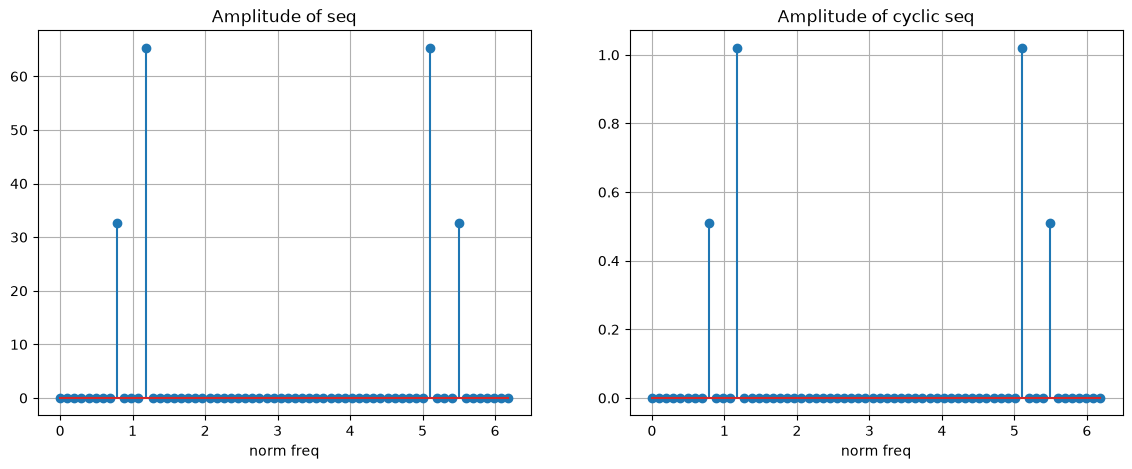

In [21]:
w, h = dft(seq)


fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].stem(w, np.abs(h))
ax[0].set_title("Amplitude of seq")
ax[0].set_xlabel("norm freq")
ax[0].grid()

ax[1].stem(w, np.abs(h) / seq_len)
ax[1].set_title("Amplitude of cyclic seq")
ax[1].set_xlabel("norm freq")
ax[1].grid()

plt.show()


Амплитудный спектр конечной последовательности и периодической отличаются нормировкой амплитуды на $1/N$

#### 5) Восстановить периодический аналоговый сигнал $x(t)$ по отсчётам ДПФ $X(k)$ периодической последовательности $x(n)$. Для вычисления значений сигнала $x(t)$ использовать формулу:

   $$
   x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a(k) \exp\left(j\frac{2\pi}{NT}kt\right),
   $$

   где отсчёты $X_a(k)$ связаны с отсчётами ДПФ $X(k)$ соотношением:

   $$
   X_a(k) =
   \begin{cases}
   X(N+k), & -N/2 \le k \le -1,\\
   X(k), & 0 \le k \le N/2-1.
   \end{cases}
   $$

   Задавая значения времени $t$ на интервале $t \in [0; (N-1)T]$ с шагом $\Delta t = 0.25T$, вывести графики:

   1. Периодической последовательности $x(n)$ и модуля её ДПФ.
   2. Восстановленного аналогового сигнала $x(t)$ и его амплитудного спектра.
   3. Исходного аналогового сигнала $x(t) = x(nT)|_{nT=t}$.


Text(0, 0.5, 'x(t)')

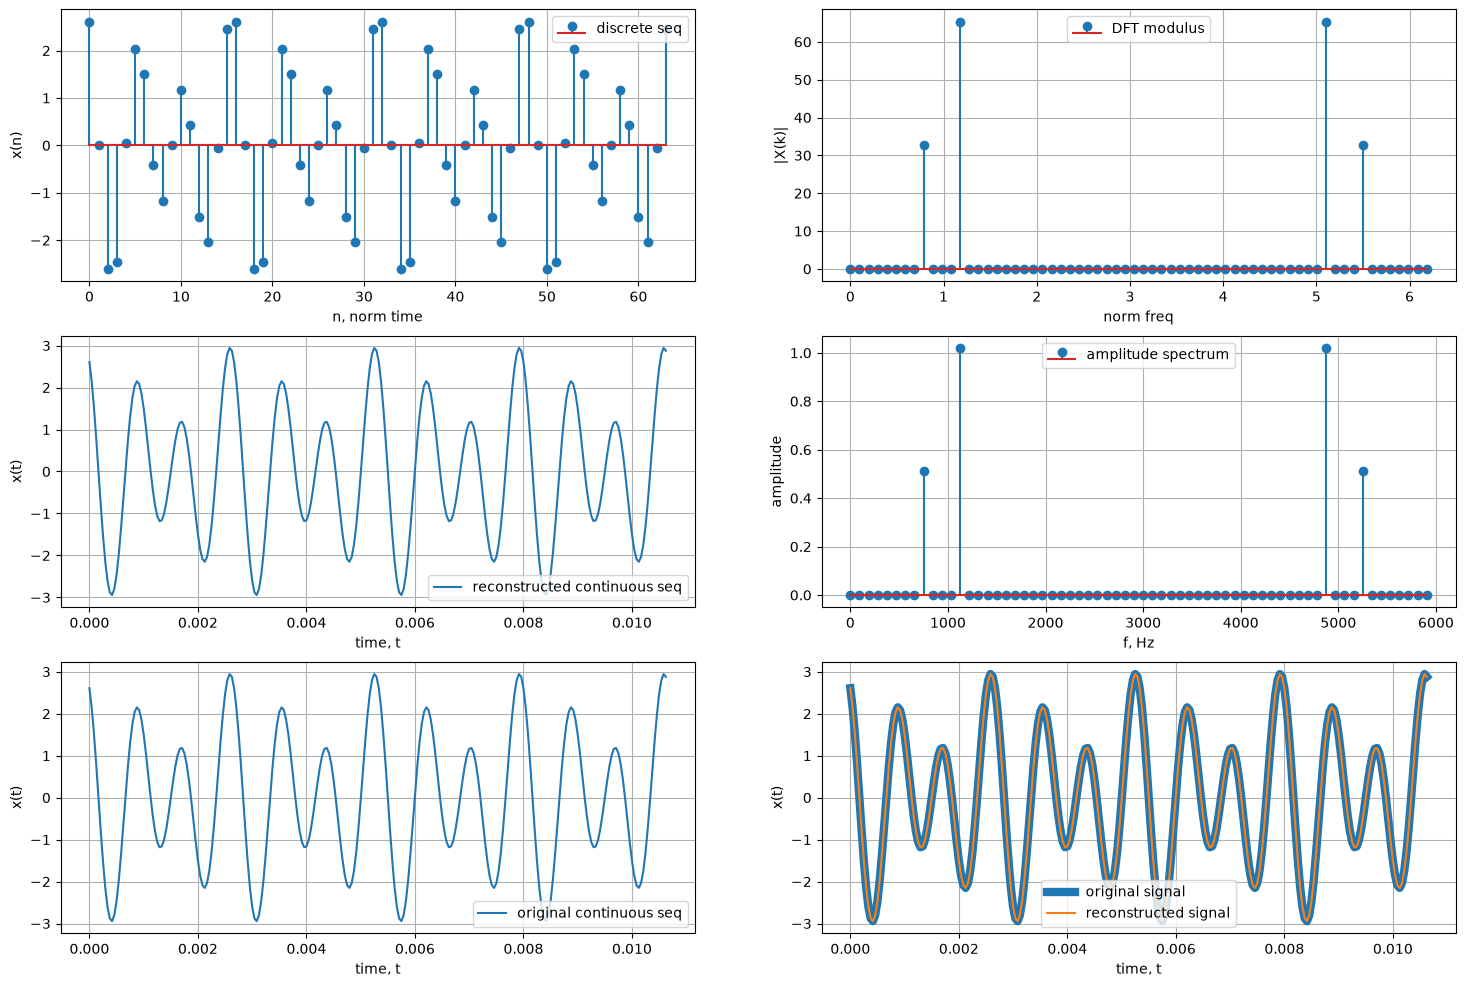

In [22]:
def continuous_signal(dft: np.ndarray, t: float) -> float:
    n = len(dft)

    res = 0.0 + 0.0j
    for k in range(-n//2, n//2):
        amp = (dft[n + k] if -n//2 <= k <= -1 else dft[k])

        wk = 2 * np.pi * k / (n*T) * 1.0j
        res += amp * np.exp(wk * t)
    
    return np.real_if_close(res/len(dft), tol=1e-6)

t = np.arange(4 * seq_len) * T / 4

w, h = dft(seq)
x_reconstructed = list(map(lambda x: continuous_signal(h, x), t))
x_original = list(map(x, t/T))

# w_a, h_a = dft(x_reconstructed)

k_a = np.arange(-seq_len // 2, seq_len // 2)
freq_a = np.arange(seq_len) / (seq_len * T)
amp_a = np.abs(h) / seq_len

fig, ax = plt.subplots(3, 2, figsize=(18, 12))

ax[0, 0].stem(range(seq_len), seq, label="discrete seq")
ax[0, 0].grid(True)
ax[0, 0].set_xlabel("n, norm time")
ax[0, 0].set_ylabel("x(n)")
ax[0, 0].legend()

ax[0, 1].grid(True)
ax[0, 1].stem(w, np.abs(h), label="DFT modulus")
ax[0, 1].set_ylabel("|X(k)|")
ax[0, 1].legend()
ax[0, 1].set_xlabel("norm freq")

ax[1, 0].plot(t, x_reconstructed, label="reconstructed continuous seq")
ax[1, 0].grid(True)
ax[1, 0].legend()
ax[1, 0].set_xlabel("time, t")
ax[1, 0].set_ylabel("x(t)")

ax[1, 1].stem(freq_a, amp_a, label="amplitude spectrum")
ax[1, 1].set_xlabel("f, Hz")
ax[1, 1].set_ylabel("amplitude")
ax[1, 1].grid(True)
ax[1, 1].legend()

ax[2, 0].plot(t, x_original, label="original continuous seq")
ax[2, 0].legend()
ax[2, 0].grid(True)
ax[2, 0].grid(True)
ax[2, 0].set_xlabel("time, t")
ax[2, 0].set_ylabel("x(t)")

ax[2, 1].plot(t, x_original, linewidth=6, label="original signal")
ax[2, 1].plot(t, x_reconstructed, label="reconstructed signal")
ax[2, 1].grid(True)
ax[2, 1].legend()
ax[2, 1].set_xlabel("time, t")
ax[2, 1].set_ylabel("x(t)")

#### 6) Исходя из результатов п. 5, объяснить:
   1. Связь модуля ДПФ последовательности со спектром аналогового сигнала.
   2. Результат визуального сравнения восстановленного и исходного сигналов.

Связь модуля ДПФ и спектра аналогового сигнала: $\dfrac{|X(k)|}{N} = A(\omega_k)$

Визульно исходный сигнал удалось восстановить идеально (график правый нижний)

#### 7) Проверить равенство Парсеваля. Пояснить его смысл.

In [23]:
lhs = np.sum(np.abs(seq) ** 2)
rhs = np.sum(np.abs(h) ** 2) / seq_len

print("Равенство Парсеваля:", np.isclose(lhs, rhs))

Равенство Парсеваля: True


Равенство Парсеваля показывает, что энергия сигнала $P_x = \sum_{n=0}^{N-1} x(n)^{2}$ во временной области равна энергии в частотной области на одном интервале.

## Выводы

В ходе выполнения лабораторной работы было изучено математическое описание линейных дискретных систем. 

В первой части работы выполнены программные расчеты импульсной характеристики ЛДС, проанализирована реакция системы на дискретный прямоугольный импульс с помощью формулы свертки. Вычислены нули и полюса ПФ системы, система оказалась устойчивой, так как все полюса находятся внутри единичного круга по критерию об устойчивости ЛДС. Вычислены АЧХ и ФЧХ, нарисованы соответствующие графики. Из графиков видно, что низкие частоты подавляются системой, а средние и высокие усиливаются. Ослабление обусловлено нахождением нулей функции вблизи границы единичного круга, а усиление нахождением полюсов вблизи границы единичного круга. 
    
Во второй части работы были вычислены ДПФ и ОДПФ для заданной периодической последовательности $x(n)$, были выведены графики амплитудного спектра и фазового спектра - оба спектра являются линейчатыми в виду того, что последовательность задана линейной комбинацией гармоник. По отсчетам был восстановлен и изображен на графике исходный аналоговый сигнал. Проверено выполнение равенства Парсеваля.